# Week 5 Part D ? Three health figures

This notebook produces three publication-ready PNG figures at 300 dpi with `bbox_inches='tight'`. The figures use the required channel decisions: population is marker area, region is categorical hue, numeric parallel-coordinate scaling and order are declared, and the district map uses projected normalized rates with explicit classification breaks and population context.


In [1]:
from pathlib import Path
import json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D
from scipy import stats

try:
    import seaborn as sns
    sns.set_theme(style='whitegrid', context='notebook')
except ImportError:
    plt.style.use('seaborn-v0_8-whitegrid')

BASE=Path.cwd()
if not (BASE/'health_indicators.csv').exists() and (BASE/'Week5').exists(): BASE=BASE/'Week5'
health=pd.read_csv(BASE/'health_indicators.csv')
district=pd.read_csv(BASE/'district_health.csv')
with open(BASE/'districts.geojson',encoding='utf-8') as f: geo=json.load(f)
features=geo['features']; geo_by_code={f['properties']['code']:f for f in features}

# Equivalent to vizlib.save_fig(): required export settings are centralized here.
def save_fig(fig,name):
    path=BASE/name; fig.savefig(path,dpi=300,bbox_inches='tight'); print('saved',path); return path

def minmax(s): return (s-s.min())/(s.max()-s.min())
def project_ring(ring):
    lat0=np.mean([p[1] for p in ring])
    return np.array([(p[0]*math.cos(math.radians(lat0)),p[1]) for p in ring])
def quantile_breaks(values,k=5):
    return np.unique(np.quantile(np.asarray(values,float),np.linspace(0,1,k+1)))
print('Loaded:',len(health),'countries,',len(district),'districts,',len(features),'geometries')


Loaded: 60 countries, 24 districts, 24 geometries


## D1 ? Four-variable bubble chart

- **x:** GDP per capita on a log scale; the extreme value is retained because it is a real observation, and the figure annotates it rather than silently deleting or clipping it.
- **y:** healthcare access with real bounds 0?100.
- **area:** population using `s=(20, 900)` points? from Part B1; `s` is area, not radius.
- **hue:** region, six categorical identities.
- **size legend:** three real population values, expressed in millions of people.


saved d:\University\ML Lab\Week5\D1_bubble.png


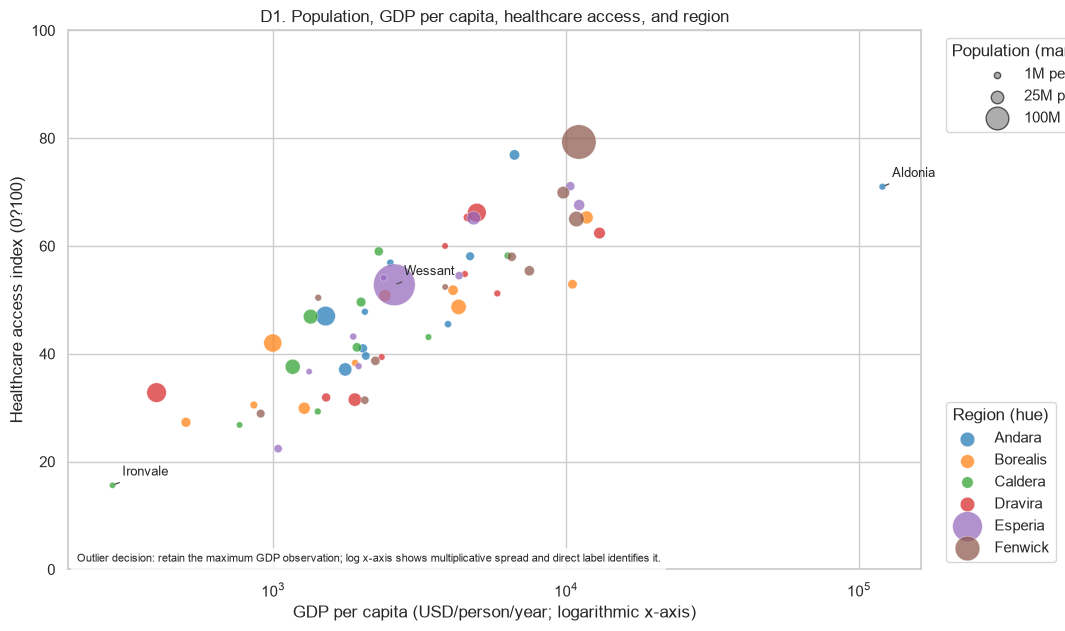

D1 size area ratio: 45.0 | diameter ratio: 6.708 | GDP outlier: Aldonia


In [2]:
sizes=(20,900); pop_min,pop_max=health.pop_m.min(),health.pop_m.max()
areas=sizes[0]+(health.pop_m-pop_min)/(pop_max-pop_min)*(sizes[1]-sizes[0])
fig,ax=plt.subplots(figsize=(11,7)); palette=plt.get_cmap('tab10'); regions=sorted(health.region.unique())
for i,region in enumerate(regions):
    g=health[health.region.eq(region)]
    ax.scatter(g.gdp_pc,g.healthcare_access,s=areas[g.index],color=palette(i),alpha=.72,edgecolor='white',linewidth=.35,label=region)
ax.set_xscale('log'); ax.set_xlim(left=200); ax.set_ylim(0,100)
ax.set(xlabel='GDP per capita (USD/person/year; logarithmic x-axis)',ylabel='Healthcare access index (0?100)',title='D1. Population, GDP per capita, healthcare access, and region')
# Direct labels for selected countries: highest population, lowest access, and GDP outlier.
selected=pd.concat([health.nlargest(1,'pop_m'),health.nsmallest(1,'healthcare_access'),health.nlargest(1,'gdp_pc')]).drop_duplicates('country')
for _,r in selected.iterrows(): ax.annotate(r.country,(r.gdp_pc,r.healthcare_access),xytext=(7,7),textcoords='offset points',fontsize=9,arrowprops={'arrowstyle':'-','color':'#555'})
# Real-value size legend: scatter s values are areas in points^2.
legend_pops=np.array([1,25,100]); legend_areas=sizes[0]+(legend_pops-pop_min)/(pop_max-pop_min)*(sizes[1]-sizes[0])
handles=[plt.scatter([],[],s=max(20,a),color='#777',alpha=.6,edgecolor='black') for a in legend_areas]
leg1=ax.legend(handles,[f'{p:g}M people' for p in legend_pops],title='Population (marker area)',loc='upper left',bbox_to_anchor=(1.02,1)); ax.add_artist(leg1)
ax.legend(title='Region (hue)',loc='lower left',bbox_to_anchor=(1.02,0))
ax.text(.01,.01,'Outlier decision: retain the maximum GDP observation; log x-axis shows multiplicative spread and direct label identifies it.',transform=ax.transAxes,fontsize=8,ha='left',va='bottom',bbox={'facecolor':'white','alpha':.8,'edgecolor':'none'})
save_fig(fig,'D1_bubble.png'); plt.show()
print('D1 size area ratio:',sizes[1]/sizes[0],'| diameter ratio:',round(math.sqrt(sizes[1]/sizes[0]),3),'| GDP outlier:',health.loc[health.gdp_pc.idxmax(),'country'])


## D2 ? Parallel coordinates

The five numeric columns are **min?max scaled** to 0?1 so different units can be compared; min?max preserves relative endpoint positions and keeps the common frame readable. The axis order is computed by the greedy chain on absolute correlation: start with the strongest connected relationship and repeatedly append the unused variable most correlated with the current endpoint. Clutter control is explicit: all countries are grey, and one region is brushed in blue.


Greedy correlation chain: ['healthcare_access', 'cases_per_100k', 'urban_pct', 'median_age', 'gdp_pc']
r(healthcare_access, cases_per_100k): -0.799
saved d:\University\ML Lab\Week5\D2_parallel_coordinates.png


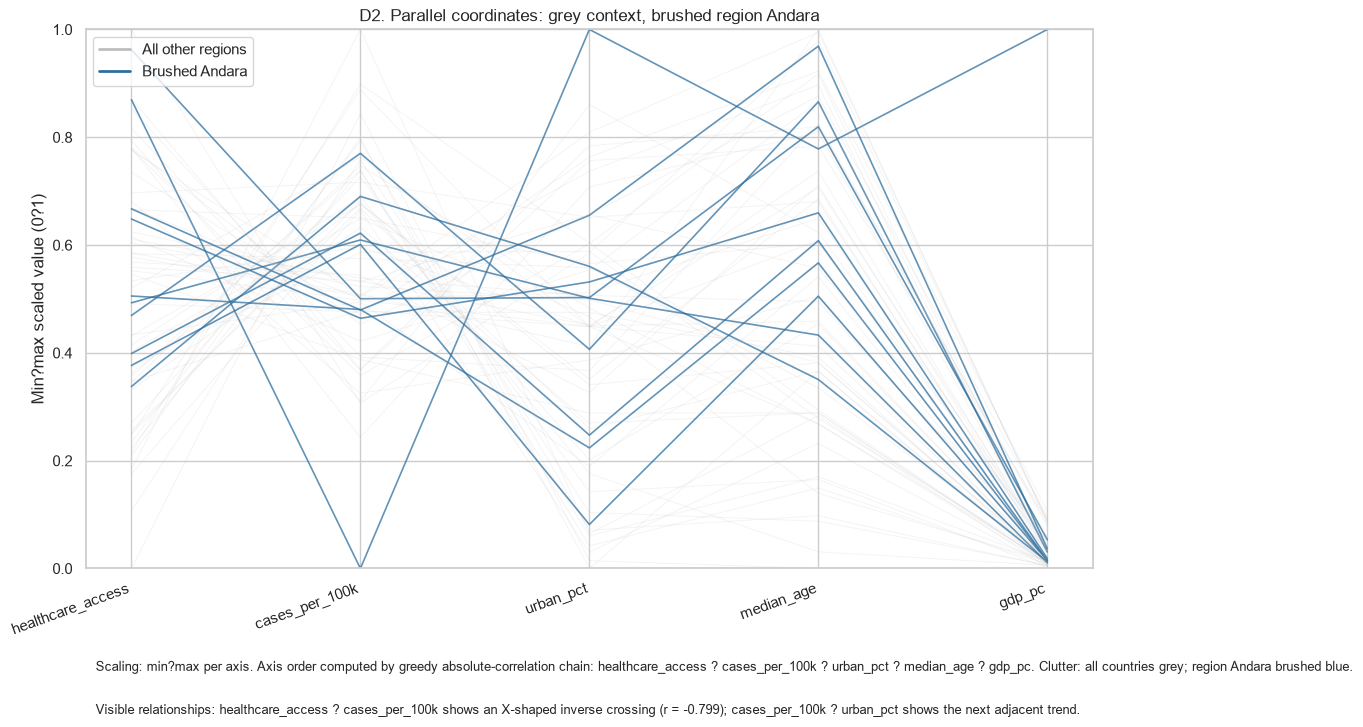

In [3]:
cols=['gdp_pc','healthcare_access','urban_pct','median_age','cases_per_100k']
# D2 uses the five numeric columns requested by the assignment: GDP, access, urban share, median age, and the already-normalized case rate.
# Greedy absolute-correlation chain, starting from the strongest pair.
corr=health[cols].corr().abs(); pairs=[(corr.loc[a,b],a,b) for i,a in enumerate(cols) for b in cols[i+1:]]
_,a,b=max(pairs); chain=[a,b]
while len(chain)<len(cols):
    unused=[x for x in cols if x not in chain]
    nxt=max(unused,key=lambda x:max(corr.loc[x,y] for y in [chain[-1]]))
    chain.append(nxt)
print('Greedy correlation chain:',chain)
print('r(healthcare_access, cases_per_100k):',round(health.healthcare_access.corr(health.cases_per_100k),3))
Z=pd.DataFrame({c:minmax(health[c]) for c in chain})
brush=health.region.iloc[0]; fig,ax=plt.subplots(figsize=(13,7)); x=np.arange(len(chain))
for i,row in Z.iterrows():
    is_brush=health.loc[i,'region']==brush; ax.plot(x,row.values,color='#2f6f9f' if is_brush else '#bdbdbd',alpha=.75 if is_brush else .16,lw=1.2 if is_brush else .7)
ax.set_xticks(x,chain,rotation=20,ha='right'); ax.set_ylim(0,1); ax.set_ylabel('Min?max scaled value (0?1)'); ax.set_title('D2. Parallel coordinates: grey context, brushed region '+str(brush))
ax.text(.01,-.19,'Scaling: min?max per axis. Axis order computed by greedy absolute-correlation chain: '+' ? '.join(chain)+'. Clutter: all countries grey; region '+str(brush)+' brushed blue.',transform=ax.transAxes,fontsize=9)
ax.text(.01,-.27,'Visible relationships: healthcare_access ? cases_per_100k shows an X-shaped inverse crossing (r = '+f'{health.healthcare_access.corr(health.cases_per_100k):.3f}'+'); cases_per_100k ? urban_pct shows the next adjacent trend.',transform=ax.transAxes,fontsize=9)
ax.legend([Line2D([0],[0],color='#bdbdbd',lw=2),Line2D([0],[0],color='#2f6f9f',lw=2)],['All other regions','Brushed '+str(brush)],loc='upper left')
save_fig(fig,'D2_parallel_coordinates.png'); plt.show()


## D3 ? Normalized choropleth with population context

Recipe: local equal-area projection before drawing/area reasoning; join on `code`; normalize to cases per 100,000 residents; use five quantile classes with printed breaks; use one sequential colour ramp where darker means higher rate; caption units, source, date, projection, and suppression rule; then place a sorted count bar chart beside the map. No district is suppressed or merged.


Join check: 24 matched; failed table rows: 0
Pooled national rate: 52.8 per 100,000 from 30564 cases
Quantile class breaks (cases per 100,000): [30.44 43.77 49.81 54.1  63.03 76.47]
Top 3 by rate: ['D19', 'D20', 'D21'] | top 3 by count: ['D17', 'D13', 'D09']
r(cases,population): 0.986
saved d:\University\ML Lab\Week5\D3_normalized_choropleth.png


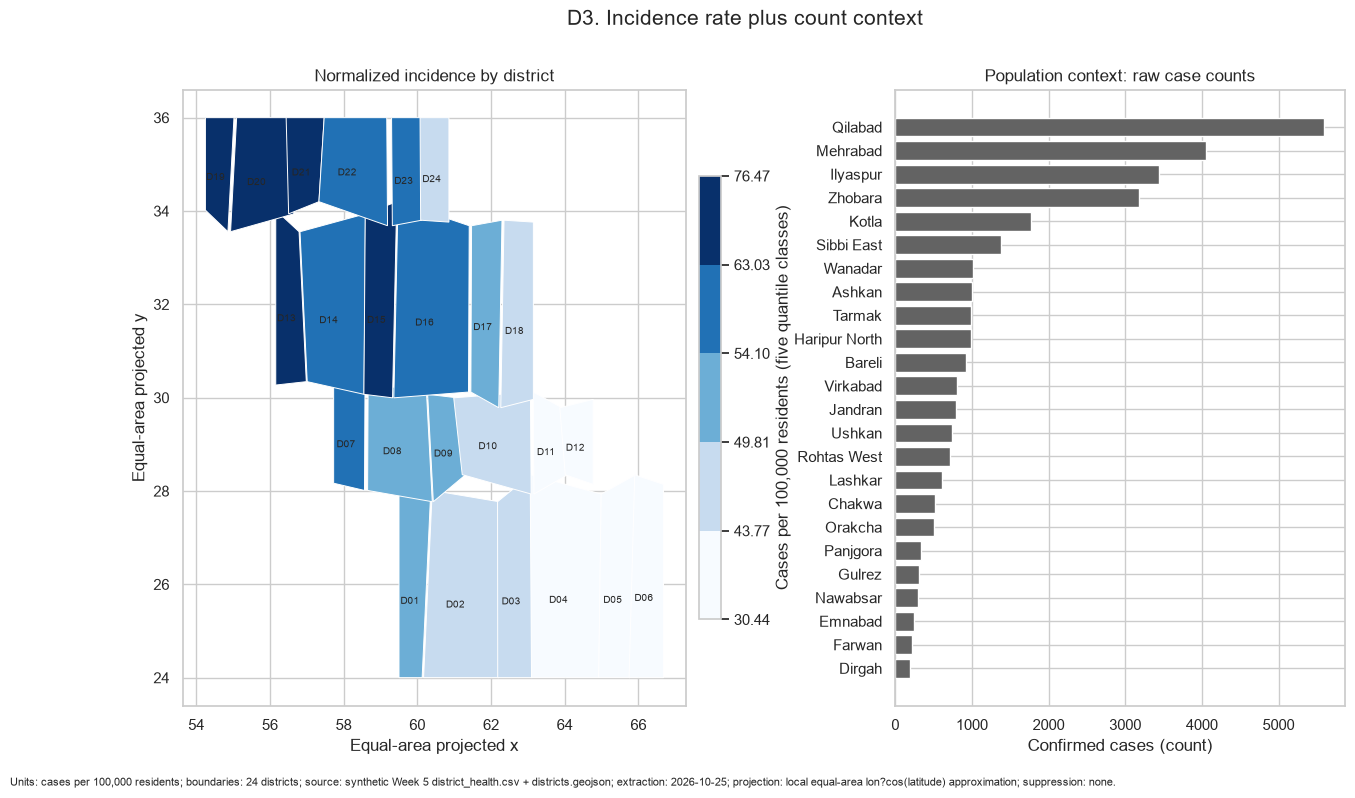

In [4]:
matched=set(district.code)&set(geo_by_code); failures=len(set(district.code)-set(geo_by_code)); print('Join check:',len(matched),'matched; failed table rows:',failures)
district=district.assign(rate=district.cases/district.population*1e5)
pooled=district.cases.sum()/district.population.sum()*1e5
rate_breaks=quantile_breaks(district.rate,5)
print('Pooled national rate:',round(pooled,1),'per 100,000 from',int(district.cases.sum()),'cases')
print('Quantile class breaks (cases per 100,000):',np.round(rate_breaks,2))
print('Top 3 by rate:',district.nlargest(3,'rate').code.tolist(),'| top 3 by count:',district.nlargest(3,'cases').code.tolist())
print('r(cases,population):',round(district.cases.corr(district.population),3))
fig,(axmap,axbar)=plt.subplots(1,2,figsize=(15,8),gridspec_kw={'width_ratios':[1.35,1]}); cmap='Blues'; norm=BoundaryNorm(rate_breaks,ncolors=plt.get_cmap(cmap).N,clip=True)
for f in features:
    code=f['properties']['code']
    if code not in matched: continue
    xy=project_ring(f['geometry']['coordinates'][0]); val=float(district.loc[district.code.eq(code),'rate'].iloc[0]); axmap.fill(xy[:,0],xy[:,1],color=plt.get_cmap(cmap)(norm(val)),ec='white',lw=.7); axmap.text(xy[:,0].mean(),xy[:,1].mean(),code,ha='center',va='center',fontsize=7)
sm=ScalarMappable(norm=norm,cmap=cmap); sm.set_array([]); cb=fig.colorbar(sm,ax=axmap,shrink=.72,pad=.02); cb.set_label('Cases per 100,000 residents (five quantile classes)')
axmap.set_title('Normalized incidence by district'); axmap.set_xlabel('Equal-area projected x'); axmap.set_ylabel('Equal-area projected y')
bar=district.sort_values('cases'); axbar.barh(bar.district,bar.cases,color='#636363'); axbar.set_xlabel('Confirmed cases (count)'); axbar.set_title('Population context: raw case counts')
fig.suptitle('D3. Incidence rate plus count context',fontsize=15)
caption='Units: cases per 100,000 residents; boundaries: 24 districts; source: synthetic Week 5 district_health.csv + districts.geojson; extraction: 2026-10-25; projection: local equal-area lon?cos(latitude) approximation; suppression: none.'
fig.text(.01,.01,caption,fontsize=8,ha='left')
save_fig(fig,'D3_normalized_choropleth.png'); plt.show()


## Export checklist

The three requested files are written into `Week5` with `dpi=300` and `bbox_inches='tight'`: `D1_bubble.png`, `D2_parallel_coordinates.png`, and `D3_normalized_choropleth.png`.
